In [4]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc

def parse_comsol_data(filepath):
    """Parse COMSOL conduit data into one row per spatial point and inlet velocity."""

    with open(filepath, 'r') as file:
        lines = file.readlines()

    header_line = None
    data_start = None
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    columns = [col.strip() for col in header_line[2:].split(';')]

    data_rows = []
    for line in lines[data_start:]:
        if line.strip():
            data_rows.append([float(x) for x in line.strip().split(';')])

    df_raw = pd.DataFrame(data_rows, columns=columns)

    grouped_columns = {}
    for col in columns[2:]:
        if '@' not in col:
            continue

        param_name, condition_text = col.split('@', 1)
        param_name = param_name.split('(')[0].strip()

        u_in = None
        for part in condition_text.split(','):
            part = part.strip()
            if '=' not in part:
                continue
            key, value = part.split('=', 1)
            if key.strip() == 'U_in':
                u_in = float(value)
                break

        if u_in is None:
            continue

        grouped_columns.setdefault(u_in, []).append((param_name, col))

    if not grouped_columns:
        raise ValueError("No columns containing a U_in condition were found.")

    records = []
    for u_in, parameter_columns in grouped_columns.items():
        for _, raw_row in df_raw.iterrows():
            record = {
                'r': raw_row[columns[0]],
                'z': raw_row[columns[1]],
                'U_in': u_in,
            }
            for param_name, original_name in parameter_columns:
                record[param_name] = raw_row[original_name]
            records.append(record)

    df_organized = pd.DataFrame(records)
    return df_organized.sort_values(['U_in', 'r', 'z']).reset_index(drop=True)

def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth +2.5e6+1e5)  # Adding 2.5 MPa offset for lithostatic pressure at surface    
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy



def parse_comsol_edge_data(filepath, var_names=None):
    """Parse COMSOL edge data into one row per spatial point and parameter set.

    Parameter values are read from the names in each COMSOL column header
    (for example ``U_in=...`` and `nu_c_max=...``), rather than being matched
    positionally. This avoids failures when the requested metadata list changes.
    """

    def _coerce_value(text):
        text = text.strip()
        try:
            value = float(text)
        except ValueError:
            return text
        return int(value) if value.is_integer() else value

    def _parse_conditions(condition_text):
        conditions = {}
        for part in condition_text.split(','):
            part = part.strip()
            if not part:
                continue
            if '=' in part:
                key, value = part.split('=', 1)
                conditions[key.strip()] = _coerce_value(value)
        return conditions

    with open(filepath, 'r') as file:
        lines = file.readlines()

    header_line = None
    data_start = None
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()[2:]
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    columns = [col.strip() for col in header_line.split(';')]
    data_rows = [
        [float(x) for x in line.strip().split(';')]
        for line in lines[data_start:]
        if line.strip()
    ]
    df_raw = pd.DataFrame(data_rows, columns=columns)

    # Keep only unique requested metadata names. If var_names is omitted,
    # retain all parameter names found in the COMSOL headers.
    requested = list(dict.fromkeys(var_names or []))

    parsed = []
    all_condition_keys = []
    for col in columns[2:]:
        if '@' not in col:
            continue
        param_text, condition_text = col.split('@', 1)
        param_name = param_text.split('(')[0].strip()
        conditions = _parse_conditions(condition_text)
        parsed.append((param_name, col, conditions))
        for key in conditions:
            if key not in all_condition_keys:
                all_condition_keys.append(key)

    if not parsed:
        raise ValueError('No parameter columns were found in the edge-data header.')

    metadata_keys = requested if requested else all_condition_keys

    # Group output variables that belong to the same model run.
    groups = {}
    for param_name, original_col, conditions in parsed:
        signature = tuple((key, conditions.get(key)) for key in metadata_keys)
        if signature not in groups:
            groups[signature] = {
                'conditions': {key: conditions.get(key) for key in metadata_keys},
                'columns': []
            }
        groups[signature]['columns'].append((param_name, original_col))

    records = []
    for group in groups.values():
        for _, raw_row in df_raw.iterrows():
            record = {
                'r': raw_row[columns[0]],
                'z': raw_row[columns[1]],
            }
            record.update(group['conditions'])
            for param_name, original_col in group['columns']:
                record[param_name] = raw_row[original_col]
            records.append(record)

    output_df = pd.DataFrame(records)

    # Drop metadata columns that were requested but never occur in the file.
    empty_metadata = [
        key for key in metadata_keys
        if key in output_df.columns and output_df[key].isna().all()
    ]
    if empty_metadata:
        output_df = output_df.drop(columns=empty_metadata)

    sort_cols = [
        col for col in ['U_in', 'nu_c_max', 'param_def', 'r', 'z']
        if col in output_df.columns
    ]
    if sort_cols:
        output_df = output_df.sort_values(sort_cols).reset_index(drop=True)

    return output_df


def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis





In [5]:
# Edge-data parser is defined once in the imports/helper-functions cell above.


In [6]:
# File path
filepath_1 = '../../data/supplimentary/Xc_growth/Xc_params_vary_conduit_wall_nu_c_max_1e3.txt'

filepath_2= '../../data/supplimentary/Xc_growth/Xc_params_vary_conduit_wall_nu_c_max_5e3.txt'

filepath_3 = '../../data/supplimentary/Xc_growth/Xc_params_vary_conduit_wall_nu_c_max_1e4.txt'


# Load and organize the data
print("Loading COMSOL conduit data...")
df_1 = parse_comsol_data(filepath_1)
df_1['nu_c_max'] = 1e3
df_2 = parse_comsol_data(filepath_2)
df_2['nu_c_max'] = 5e3
df_3 = parse_comsol_data(filepath_3)
df_3['nu_c_max'] = 1e4


# Combine dataframes
df = pd.concat([df_1, df_2, df_3], ignore_index=True)

# Load and organize the data
print("Loading COMSOL conduit data...")
# df = parse_comsol_data(filepath_flow)




Loading COMSOL conduit data...


Loading COMSOL conduit data...


In [7]:
df

,r,z,U_in,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,rho_m,Xm,T,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw,nu_c_max
0,15.0,-3000.00000,0.00001,0.40000,0.40000,0.0,0.0,4.036200e-01,2700.0,2700.0,0.60000,1223.0,82867000.0,32961.0,1.0,4.5918,151350.0,0.00001,0.030000,1000.0
1,15.0,-2999.80000,0.00001,0.39994,0.39994,0.0,0.0,4.035000e-01,2700.0,2700.0,0.60006,1223.0,82862000.0,32961.0,1.0,4.5901,151300.0,0.00001,0.030000,1000.0
2,15.0,-2999.70000,0.00001,0.39990,0.39990,0.0,0.0,4.034400e-01,2700.0,2700.0,0.60010,1223.0,82858000.0,32961.0,1.0,4.5891,151260.0,0.00001,0.030000,1000.0
3,15.0,-2999.50000,0.00001,0.39988,0.39988,0.0,0.0,4.034100e-01,2700.0,2700.0,0.60012,1223.0,82853000.0,32961.0,1.0,4.5886,151250.0,0.00001,0.030000,1000.0
4,15.0,-2999.30000,0.00001,0.39987,0.39987,0.0,0.0,4.034000e-01,2700.0,2700.0,0.60013,1223.0,82849000.0,32961.0,1.0,4.5884,151240.0,0.00001,0.030000,1000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
776383,15.0,-0.69268,0.31623,0.41847,0.41847,0.0,0.0,3.505600e+06,2700.0,2700.0,0.58153,1223.0,2817600.0,12356000.0,1.0,5.1177,63233000.0,0.30760,0.002578,10000.0
776384,15.0,-0.51933,0.31623,0.41847,0.41847,0.0,0.0,3.501700e+06,2700.0,2700.0,0.58153,1223.0,2737100.0,12361000.0,1.0,5.1178,63259000.0,0.30758,0.002577,10000.0
776385,15.0,-0.34610,0.31623,0.41848,0.41848,0.0,0.0,3.498500e+06,2700.0,2700.0,0.58152,1223.0,2655800.0,12364000.0,1.0,5.1180,63277000.0,0.30756,0.002577,10000.0
776386,15.0,-0.17299,0.31623,0.41848,0.41848,0.0,0.0,3.496400e+06,2700.0,2700.0,0.58152,1223.0,2573700.0,12365000.0,1.0,5.1181,63287000.0,0.30755,0.002576,10000.0


In [8]:


filepath_edge = r'../../data/supplimentary/Xc_growth/Xc_params_vary_ground_edge_nu_c_max.txt'

var_names = ['U_in', 'nu_c_max', 'tau_Xc', 'Xc_max', 'param_def']
df_ge = parse_comsol_edge_data(filepath_edge, var_names)



In [9]:
# Display basic information about the dataset
print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")


# Display first few rows
print(f"\nFirst 5 rows:")
print(df.head())

# Display summary statistics
print(f"\nSummary statistics:")
print(df.describe())


Dataset loaded successfully!
Shape: (776388, 20)
Columns: ['r', 'z', 'U_in', 'Xc_nocap', 'Xc', 'Sb', 'Xg', 'spf.mu*spf.sr', 'rho_b', 'rho_m', 'Xm', 'T', 'linproj_r', 'mu_m', 'nu_b_inf', 'nu_c', 'mu_mbc', 'u_av', 'Cw', 'nu_c_max']

First 5 rows:
      r       z     U_in  Xc_nocap       Xc   Sb   Xg  spf.mu*spf.sr   rho_b  \
0  15.0 -3000.0  0.00001   0.40000  0.40000  0.0  0.0        0.40362  2700.0   
1  15.0 -2999.8  0.00001   0.39994  0.39994  0.0  0.0        0.40350  2700.0   
2  15.0 -2999.7  0.00001   0.39990  0.39990  0.0  0.0        0.40344  2700.0   
3  15.0 -2999.5  0.00001   0.39988  0.39988  0.0  0.0        0.40341  2700.0   
4  15.0 -2999.3  0.00001   0.39987  0.39987  0.0  0.0        0.40340  2700.0   

    rho_m       Xm       T   linproj_r     mu_m  nu_b_inf    nu_c    mu_mbc  \
0  2700.0  0.60000  1223.0  82867000.0  32961.0       1.0  4.5918  151350.0   
1  2700.0  0.60006  1223.0  82862000.0  32961.0       1.0  4.5901  151300.0   
2  2700.0  0.60010  1223.0  82858000

In [10]:
df_ge

,r,z,U_in,nu_c_max,tau_Xc,Xc_max,param_def,u2,v2,w2,solid.RotrZ
0,15.000,0.000000e+00,0.00001,1000,0.0001,0.75,1,-0.000104,0.0,0.002561,3.365000e-04
1,15.183,2.273700e-13,0.00001,1000,0.0001,0.75,1,-0.000094,0.0,0.002507,2.392600e-04
2,15.385,2.273700e-13,0.00001,1000,0.0001,0.75,1,-0.000085,0.0,0.002464,1.951100e-04
3,15.608,2.273700e-13,0.00001,1000,0.0001,0.75,1,-0.000075,0.0,0.002423,1.673100e-04
4,15.855,2.273700e-13,0.00001,1000,0.0001,0.75,1,-0.000064,0.0,0.002385,1.469000e-04
...,...,...,...,...,...,...,...,...,...,...,...
12139,2368.500,-8.764600e+02,0.31623,10000,0.0001,0.75,1,0.002726,0.0,0.001903,1.578800e-06
12140,2552.100,-9.529800e+02,0.31623,10000,0.0001,0.75,1,0.002464,0.0,0.001690,1.414100e-06
12141,2756.200,-1.038000e+03,0.31623,10000,0.0001,0.75,1,0.002191,0.0,0.001484,1.254800e-06
12142,2992.200,-1.136300e+03,0.31623,10000,0.0001,0.75,1,0.001894,0.0,0.001282,1.097300e-06


In [11]:
from matplotlib.colors import LogNorm


def plot_conduit_analysis_fig1(
    df,
    df_ge,
    colormap='batlow',
    figsize=(7, 10),
    save_plot=True,
    station_distances=(100, 500),
    param_def=1
):
    """
    Plot the effect of nu_c_max on inlet excess pressure and deformation.

    Layout
    ------
    Top:
        Inlet excess pressure versus inlet velocity,
        one line per nu_c_max, with legend to the right.

    Bottom:
        Two columns corresponding to 100 m and 500 m
        from the conduit.

        Row 1: vertical displacement (uz)
        Row 2: radial displacement (ur)
        Row 3: tilt

    Colour represents nu_c_max throughout the figure.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import string
    from matplotlib.lines import Line2D
    from matplotlib.colors import LogNorm, Normalize

    # --------------------------------------------------------------
    # Plot styling
    # --------------------------------------------------------------
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica',
            'Arial',
            'Liberation Sans',
            'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 9,
        'figure.titlesize': 11
    })

    # --------------------------------------------------------------
    # Prepare conduit data
    # --------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    print(f"Debug: df_analysis columns: {df_analysis.columns}")
    if 'nu_c_max' not in df_analysis.columns:
        raise KeyError("df must contain a 'nu_c_max' column.")

    if 'nu_c_max' not in df_ge.columns:
        raise KeyError("df_ge must contain a 'nu_c_max' column.")

    nu_c_max_values = np.array(
        sorted(df_analysis['nu_c_max'].dropna().astype(float).unique()),
        dtype=float
    )

    if len(nu_c_max_values) == 0:
        raise ValueError("No nu_c_max values were found.")

    # --------------------------------------------------------------
    # Colour mapping
    # --------------------------------------------------------------
    cmap = get_colormap(colormap)

    if len(nu_c_max_values) == 1:
        nu_c_max_to_color = {
            nu_c_max_values[0]: cmap(0.55)
        }

    elif np.all(nu_c_max_values > 0):
        nu_c_max_norm = LogNorm(
            vmin=nu_c_max_values.min(),
            vmax=nu_c_max_values.max()
        )

        nu_c_max_to_color = {
            nu_c_max: cmap(nu_c_max_norm(nu_c_max))
            for nu_c_max in nu_c_max_values
        }

    else:
        nu_c_max_norm = Normalize(
            vmin=nu_c_max_values.min(),
            vmax=nu_c_max_values.max()
        )

        nu_c_max_to_color = {
            nu_c_max: cmap(nu_c_max_norm(nu_c_max))
            for nu_c_max in nu_c_max_values
        }

    # --------------------------------------------------------------
    # Find deformation columns
    # --------------------------------------------------------------
    def find_column(frame, candidates, suffixes=()):
        for name in candidates:
            if name in frame.columns:
                return name

        for col in frame.columns:
            col_lower = str(col).lower()

            for suffix in suffixes:
                if col_lower.endswith(suffix.lower()):
                    return col

        return None

    w2_col = find_column(
        df_ge,
        [ 'w2'],
        suffixes=('.w2', 'w2')
    )

    u2_col = find_column(
        df_ge,
        [ 'u2'],
        suffixes=('.u2', 'u2')
    )

    tilt_col = find_column(
        df_ge,
        ['solid.RotrZ', 'RotrZ'],
        suffixes=('.rotrz', 'rotrz')
    )

    missing = [
        label
        for label, col in [
            ('vertical displacement (w2)', w2_col),
            ('radial displacement (u2)', u2_col),
            ('tilt (solid.RotrZ)', tilt_col)
        ]
        if col is None
    ]

    if missing:
        raise KeyError(
            "Could not find the following edge-data columns: "
            + ", ".join(missing)
            + f"\nAvailable columns are:\n{list(df_ge.columns)}"
        )

    # --------------------------------------------------------------
    # Check stations
    # --------------------------------------------------------------
    if len(station_distances) != 2:
        raise ValueError(
            "station_distances must contain exactly two distances, "
            "for example (100, 500)."
        )

    # --------------------------------------------------------------
    # Figure layout
    #
    # Top section:
    #   pressure plot + legend space
    #
    # Bottom section:
    #   full-width 3 x 2 grid
    # --------------------------------------------------------------
    fig = plt.figure(figsize=figsize)

    outer_gs = fig.add_gridspec(
        nrows=3,
        ncols=1,
        height_ratios=[1.15, 0.30, 3.0],
        hspace=0.15
    )

    # --------------------------------------------------------------
    # TOP SECTION
    # --------------------------------------------------------------
    top_gs = outer_gs[0].subgridspec(
        nrows=1,
        ncols=3,
        width_ratios=[1, 1, 0.55],
        wspace=0.08
    )

    ax_top = fig.add_subplot(top_gs[0, 0:2])

    ax_legend = fig.add_subplot(top_gs[0, 2])
    ax_legend.axis('off')

    # --------------------------------------------------------------
    # BOTTOM SECTION
    # --------------------------------------------------------------
    bottom_gs = outer_gs[2].subgridspec(
        nrows=3,
        ncols=2,
        hspace=0.25,
        wspace=0.28
    )

    deformation_axes = np.array([
        [
            fig.add_subplot(bottom_gs[0, 0]),
            fig.add_subplot(bottom_gs[0, 1])
        ],
        [
            fig.add_subplot(bottom_gs[1, 0]),
            fig.add_subplot(bottom_gs[1, 1])
        ],
        [
            fig.add_subplot(bottom_gs[2, 0]),
            fig.add_subplot(bottom_gs[2, 1])
        ]
    ])

    # --------------------------------------------------------------
    # TOP PANEL
    # Inlet excess pressure vs inlet velocity
    # --------------------------------------------------------------
    df_top = df_analysis.copy()

    for nu_c_max in nu_c_max_values:

        df_tau = df_top[
            np.isclose(
                df_top['nu_c_max'].astype(float),
                nu_c_max
            )
        ].copy()

        points = []

        for velocity in sorted(
            df_tau['U_in'].dropna().astype(float).unique()
        ):

            df_vel = df_tau[
                np.isclose(
                    df_tau['U_in'].astype(float),
                    velocity
                )
            ]

            if df_vel.empty:
                continue

            deepest_idx = df_vel['z'].astype(float).idxmin()

            pressure_mpa = (
                float(df_vel.loc[deepest_idx, 'P_excess'])
                / 1e6
            )

            points.append(
                (velocity, pressure_mpa)
            )

        if not points:
            continue

        points = np.asarray(
            points,
            dtype=float
        )

        points = points[
            np.argsort(points[:, 0])
        ]

        ax_top.semilogx(
            points[:, 0],
            points[:, 1],
            color=nu_c_max_to_color[nu_c_max],
            linewidth=1.5
        )

    ax_top.set_ylabel(
        r'Inlet $\Delta P$ (MPa)'
    )

    ax_top.set_xlabel(
        'Inlet velocity (m/s)',
        labelpad=2
    )

    ax_top.set_title(
        r'Effect of varying $\mu_{c,\mathrm{max}}$ on syn-eruptive crystallisation'
    )

    ax_top.grid(
        True,
        which='major',
        alpha=0.3
    )

    ax_top.grid(
        True,
        which='minor',
        axis='x',
        alpha=0.12,
        linestyle=':'
    )

    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)

    # --------------------------------------------------------------
    # BOTTOM PANELS
    #
    # w2 and u2 converted from m to mm
    # tilt converted from rad to microrad
    # --------------------------------------------------------------
    deformation_specs = [
        (
            w2_col,
            r'$u_z$ (mm)',
            1e3
        ),
        (
            u2_col,
            r'$u_r$ (mm)',
            1e3
        ),
        (
            tilt_col,
            r'Tilt ($\mu$rad)',
            1e6
        )
    ]

    edge_base = df_ge.copy()

    # Select deformation parameter set if present
    if 'param_def' in edge_base.columns:

        edge_base = edge_base[
            np.isclose(
                edge_base['param_def'].astype(float),
                float(param_def)
            )
        ].copy()

    # --------------------------------------------------------------
    # Loop through deformation rows and station columns
    # --------------------------------------------------------------
    for row_idx, (var, ylabel, scale) in enumerate(
        deformation_specs
    ):

        for col_idx, station_distance in enumerate(
            station_distances
        ):

            ax = deformation_axes[
                row_idx,
                col_idx
            ]

            # ------------------------------------------------------
            # Select distance from conduit
            # ------------------------------------------------------
            df_station = edge_base[
                np.isclose(
                    edge_base['r'].astype(float),
                    float(station_distance)
                )
            ].copy()

            if df_station.empty:
                print(
                    f'Warning: no edge data found at '
                    f'r = {station_distance} m'
                )

            # ------------------------------------------------------
            # Plot one line per nu_c_max
            # ------------------------------------------------------
            for nu_c_max in nu_c_max_values:

                df_tau = df_station[
                    np.isclose(
                        df_station['nu_c_max'].astype(float),
                        nu_c_max
                    )
                ].copy()

                if df_tau.empty:
                    continue

                if var not in df_tau.columns:
                    continue

                plot_df = (
                    df_tau[['U_in', var]]
                    .dropna()
                    .astype(float)
                    .groupby(
                        'U_in',
                        as_index=False
                    )[var]
                    .mean()
                    .sort_values('U_in')
                )

                if plot_df.empty:
                    continue

                ax.semilogx(
                    plot_df['U_in'],
                    plot_df[var] * scale,
                    color=nu_c_max_to_color[nu_c_max],
                    linewidth=1.5
                )

            # ------------------------------------------------------
            # Panel formatting
            # ------------------------------------------------------
            if row_idx == 0:
                ax.set_title(
                    f'r = {station_distance} m ',
                    pad=7
                )

            if col_idx == 0:
                ax.set_ylabel(ylabel)

            if row_idx == len(deformation_specs) - 1:
                ax.set_xlabel(
                    'Inlet velocity (m/s)'
                )
            else:
                ax.tick_params(
                    axis='x',
                    labelbottom=False
                )

            ax.grid(
                True,
                which='major',
                alpha=0.3
            )

            ax.grid(
                True,
                which='minor',
                axis='x',
                alpha=0.12,
                linestyle=':'
            )

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

    # --------------------------------------------------------------
    # tau_Xc legend
    # --------------------------------------------------------------
    legend_handles = [
        Line2D(
            [0],
            [0],
            color=nu_c_max_to_color[nu_c_max],
            linewidth=1.8,
            label=rf'${nu_c_max:.0e}$'
        )
        for nu_c_max in nu_c_max_values
    ]

    ax_legend.legend(
        handles=legend_handles,
        title=r'$\mu_{c,\mathrm{max}}$',
        loc='center',
        frameon=True,
        fancybox=False,
        edgecolor='black',
        facecolor='white',
        framealpha=1.0,
        ncol=1,
        handlelength=2.2,
        borderpad=0.8,
        labelspacing=0.6
    )

    # --------------------------------------------------------------
    # Panel labels
    # --------------------------------------------------------------
    axes_to_label = (
        [ax_top]
        + list(deformation_axes.ravel())
    )

    for label, ax in zip(
        string.ascii_uppercase,
        axes_to_label
    ):

        ax.text(
            0.98,
            0.04,
            label,
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom',
            ha='right'
        )

    # --------------------------------------------------------------
    # Alignment and margins
    # --------------------------------------------------------------
    fig.align_ylabels(
        deformation_axes[:, 0]
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.97,
        bottom=0.07,
        top=0.96
    )

    # --------------------------------------------------------------
    # Save
    # --------------------------------------------------------------
    if save_plot:

        fig.savefig(
            '../../output_plots/2/'
            f'Supplimentary_nu_c_max_deformation_{colormap}.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            '../../output_plots/2/'
            f'Supplimentary_nu_c_max_deformation_{colormap}.pdf',
            dpi=300,
            bbox_inches='tight'
        )

    return fig

In [12]:

def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - ((rho_e * g * depth)) # Adding 2.5 MPa offset for lithostatic pressure at surface    
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


Creating conduit analysis plot...
Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209300.0 to 101830000.0
Debug: P_excess range: 2177158.0255 to 22369000.0
Debug: df_analysis columns: Index(['r', 'z', 'U_in', 'Xc_nocap', 'Xc', 'Sb', 'Xg', 'spf.mu*spf.sr',
       'rho_b', 'rho_m', 'Xm', 'T', 'linproj_r', 'mu_m', 'nu_b_inf', 'nu_c',
       'mu_mbc', 'u_av', 'Cw', 'nu_c_max', 'P_excess'],
      dtype='str')


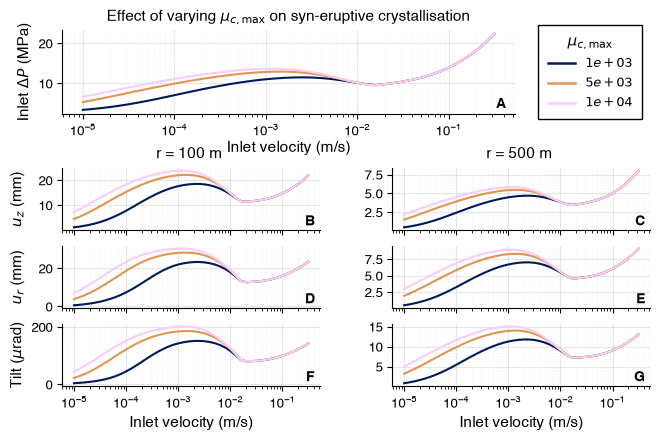

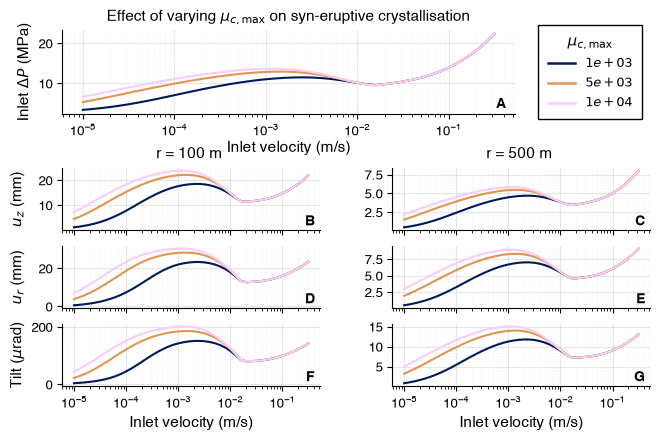

In [13]:
# Create the updated nu_c_max / deformation figure
print("\nCreating conduit analysis plot...")
plot_conduit_analysis_fig1(
    df,
    df_ge,
    colormap='batlow',
    figsize=(7, 4),
    save_plot=True,
    station_distances=(100, 500),
    param_def=1
)


In [14]:
# The plotting function is defined in cell 8 and called in cell 10.
